In [1]:
library(tidyverse)

Warning message:
"package 'tidyverse' was built under R version 4.6.1"


Warning message:
"package 'ggplot2' was built under R version 4.6.1"


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


### CSV 파일 불러오기

In [2]:
# 수정: 4장대로 read_csv()로 읽어 날짜 열을 날짜형으로 받는다(read.csv()는 문자열로 읽음)
daily <- read_csv("../dataset/working/daily.csv")
nrow(daily)   # 365

Rows: 365 Columns: 7


── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): 요일
dbl  (3): 승차, 기온, 강수량
lgl  (2): 주말, 비
date (1): 날짜



ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 365

#### **01_기초통계 : min, qunatile1~3, min, max, sd**

In [3]:
daily %>% 
    summarise(최소 = min(승차),
            Q1 = quantile(승차, 0.25),
            Q2 = quantile(승차, 0.5),
            Q3 = quantile(승차, 0.75),
            최대 = max(승차),
            표준편차 = sd(승차))

최소,Q1,Q2,Q3,최대,표준편차
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1449017,3666626,4915572,5175074,5663933,987921.6


**A. 기초통계 : 시각화 (boxplot)**

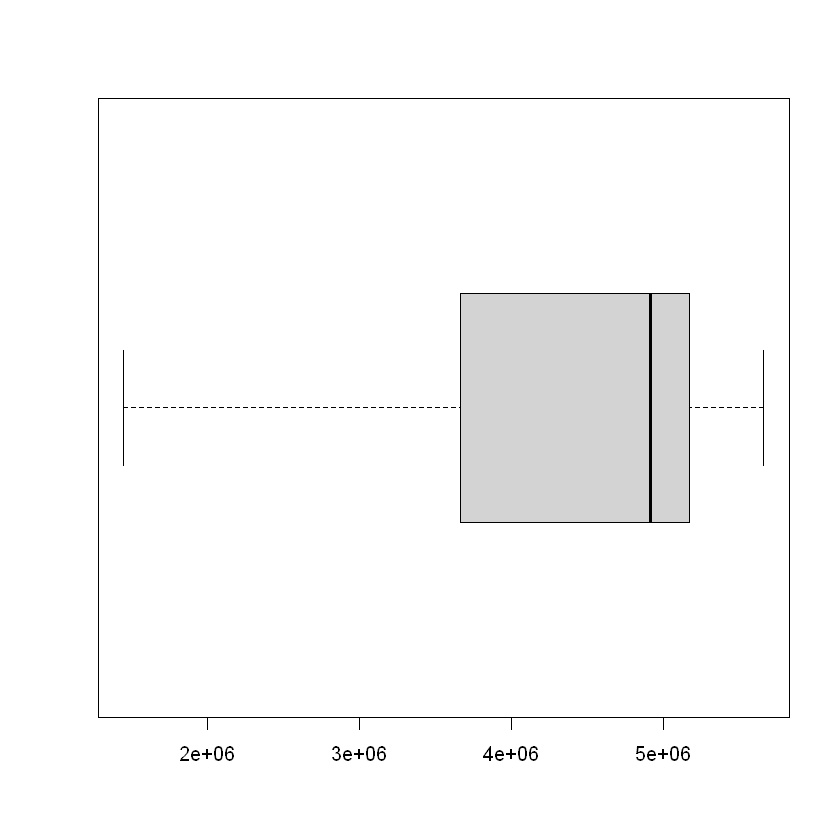

In [4]:
boxplot(daily$승차, horizontal = TRUE)

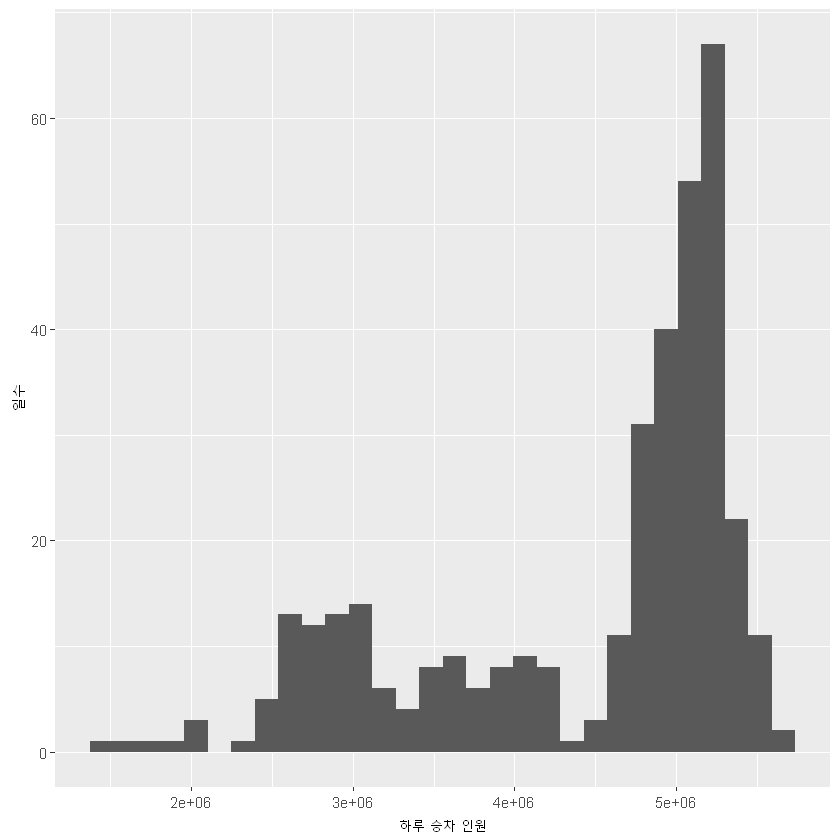

In [5]:
ggplot(daily, aes(x = 승차)) +
  geom_histogram(bins = 30) +
  labs(x = "하루 승차 인원", y = "일수")

In [6]:
# 주말 열은 4장 daily.csv에 이미 있다. 같은 값으로 다시 만들어도 결과는 같다
daily <- daily %>% mutate(주말 = wday(날짜) %in% c(1, 7))

In [7]:
daily %>% 
    group_by(주말) %>%
    summarise(일수 = n(),
            평균 = mean(승차),
            표준편차 = sd(승차))

주말,일수,평균,표준편차
<lgl>,<int>,<dbl>,<dbl>
FALSE,261,4902412,694148.7
TRUE,104,3278359,573136.5


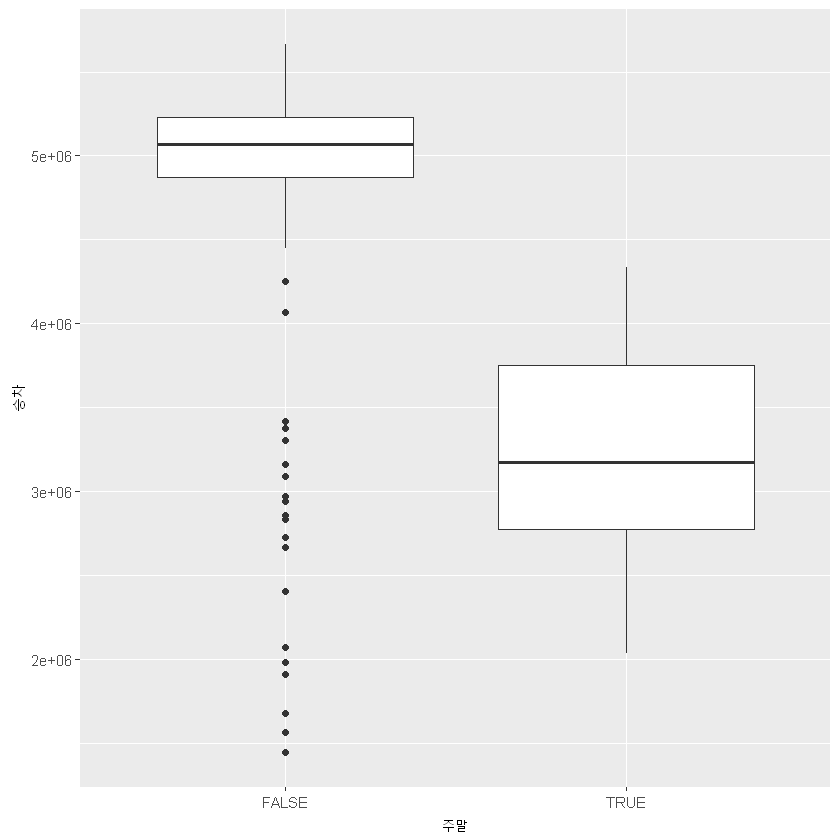

In [8]:
ggplot(data = daily, mapping = aes(x=주말, y=승차)) +
    geom_boxplot()

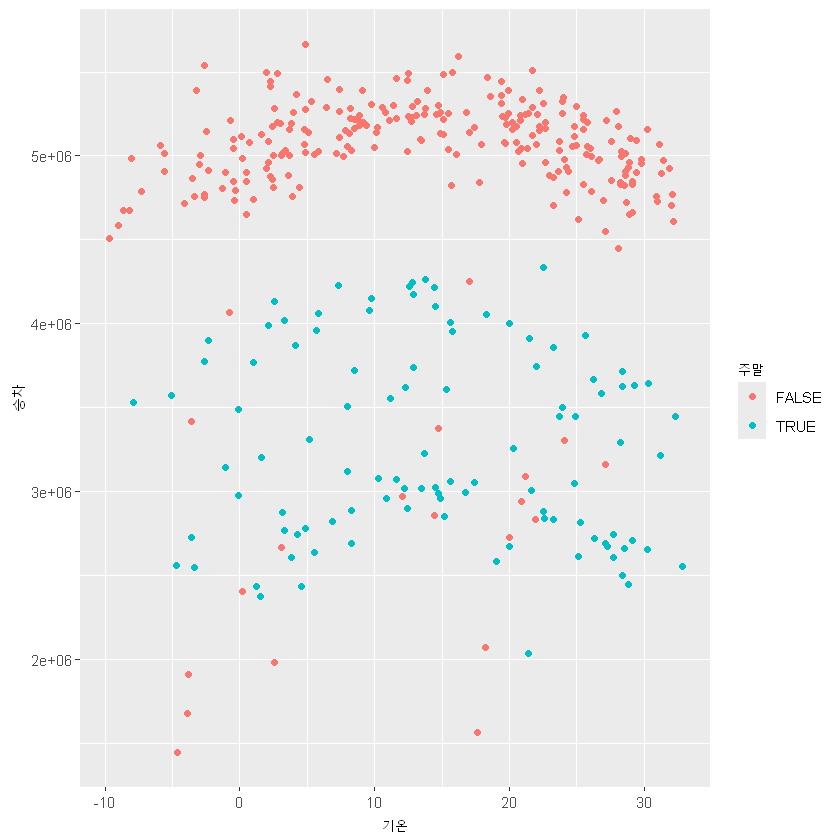

In [9]:
ggplot(data = daily, mapping = aes(x=기온, y=승차, colour = 주말)) +
    geom_point()

In [10]:
daily %>% 
    group_by(비) %>%
    summarise(일수 = n(), 
            평균승차 = mean(승차))

비,일수,평균승차
<lgl>,<int>,<dbl>
FALSE,248,4539584
TRUE,117,4227880


In [11]:
# 수정: daily.csv에 주말 열이 다시 들어가서 강의 코드 그대로 실행된다
daily %>%
    group_by(주말, 비) %>%
    summarise(일수 = n(),
            평균승차 = mean(승차),
            .groups = "drop")

주말,비,일수,평균승차
<lgl>,<lgl>,<int>,<dbl>
FALSE,FALSE,185,4981198
FALSE,TRUE,76,4710631
TRUE,FALSE,63,3242783
TRUE,TRUE,41,3333024


##### **[수업과 다르게 진행한 사항]**

다음 코드에서 오류가 떠서 아래 코드로 수정하여 진행함. 
<br>

<기존코드>
```R
daily %>%
    group_by(.data = 주말, 비) %>%
    summarise(일수 = n(),
            평균승차 = mean(하루),
            .groups = "drops")
```
<br>

<에러>
```markdown
Error: object '주말' not found
Traceback:

1. summarise(., 일수 = n(), 평균승차 = mean(하루), .groups = "drops")
2. group_by(., .data = 주말, 비)
3. .handleSimpleError(function (cnd) 
 . {
 .     watcher$capture_plot_and_output()
 .     cnd <- sanitize_call(cnd)
 .     watcher$push(cnd)
 .     switch(on_error, continue = invokeRestart("eval_continue"), 
 .         stop = invokeRestart("eval_stop"), error = NULL)
 . }, "object '주말' not found", base::quote(NULL))
```
<br>

<수정 코드>
```R
daily %>%
    mutate(주말 = as.POSIXlt(as.Date(날짜))$wday %in% c(0, 6)) %>%
    group_by(주말, 비) %>%
    summarise(
        일수 = n_distinct(날짜),
        평균승차 = mean(하루, na.rm = TRUE),
        .groups = "drop")
```


<br>

**[원인 정리]** `object '주말' not found` 오류의 진짜 원인은 4장 노트북에서 `daily`를 역 단위 표(`subway %>% left_join(weather)`)로 덮어써서 `daily.csv`에 `주말` 열이 저장되지 않은 것이었다. 기존 코드의 `group_by(.data = 주말, 비)`와 `.groups = "drops"`도 오타다(`group_by(주말, 비)`, `.groups = "drop"`). 4장 노트북을 고쳐 `daily.csv`를 하루 단위(365행)로 다시 만든 뒤 강의 코드 그대로 실행했다.